# Digital Image Processing Lab – Lab Task # 05
## Spatial Filtering and Convolution

**Name:** SAQLAIN MUSHTAQ  
**Roll No:** 2024-SE-35 
**Session:** 2024-28 (SE) | **Semester:** Fifth | **Instructor:** Engr. Fahad Nisar  
**University of Azad Jammu and Kashmir – Department of Software Engineering**

**Objective:** Implement 2-D convolution from first principles, apply mean, Gaussian and median filters to remove noise from real images, verify hand calculations and compare against OpenCV.

**Rules followed:** R1 same size + reflect padding · R2 float64, round + clip only at the end · R3 smoothing weights sum to 1 · R4 odd kernels only (3, 5, 7) · R5 seed = 5 · R6 judge against the clean original.

## 0. Setup

In [1]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

SEED = 5                      # R5: every noise function uses seed=5
print("NumPy :", np.__version__)
print("OpenCV:", cv2.__version__)

NumPy : 2.4.6
OpenCV: 5.0.0


## 1. Load the three real test images
`camera`, `coins` and `chelsea` (converted to grayscale) come from `skimage.data`. To keep the GitHub repository small, every image is shrunk once to **at most 256 px** on its longest side and saved as a ~30 KB PNG in `images/` (if `skimage.data` is ever unavailable the notebook automatically reads those saved copies). The arrays are then set **read-only**, so the originals can never change.

In [2]:
IMG_DIR = "images"            # small PNG copies are stored here (easy to push to GitHub)
os.makedirs(IMG_DIR, exist_ok=True)
NAMES = ["camera", "coins", "chelsea"]

def shrink(a, max_side=256):
    """Downscale (keeps aspect ratio) so the repository stays tiny and the loops run fast."""
    h, w = a.shape[:2]
    s = max_side / max(h, w)
    if s >= 1:
        return a
    return cv2.resize(a, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def load_from_skimage():
    return {
        "camera": data.camera(),                                          # already grayscale
        "coins": data.coins(),                                            # already grayscale
        "chelsea": cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2GRAY),      # colour -> grayscale
    }

def load_from_folder():
    out = {}
    for n in NAMES:
        im = cv2.imread(os.path.join(IMG_DIR, n + ".png"), cv2.IMREAD_GRAYSCALE)
        if im is None:
            return None
        out[n] = im
    return out

try:
    raw, source = load_from_skimage(), "skimage.data"
except Exception:                 # e.g. no internet / missing dataset -> use the saved copies
    raw, source = load_from_folder(), "images/ folder"

originals = {}
for n in NAMES:
    img = np.ascontiguousarray(shrink(raw[n]), dtype=np.uint8)
    path = os.path.join(IMG_DIR, n + ".png")
    if not os.path.exists(path):
        cv2.imwrite(path, img)
    img.flags.writeable = False   # originals can never be modified by accident
    originals[n] = img

print("Images loaded from:", source)
for n, im in originals.items():
    print(f"{n:8s} shape={im.shape}  dtype={im.dtype}  min={im.min()}  max={im.max()}  "
          f"file size={os.path.getsize(os.path.join(IMG_DIR, n + '.png')) / 1024:.1f} KB")

Images loaded from: skimage.data
camera   shape=(256, 256)  dtype=uint8  min=2  max=255  file size=36.5 KB
coins    shape=(202, 256)  dtype=uint8  min=4  max=239  file size=33.7 KB
chelsea  shape=(170, 256)  dtype=uint8  min=5  max=193  file size=27.0 KB


## 2. `conv2d_loop` – 2-D convolution from scratch
For every pixel the kernel is slid over a small window; the window values are multiplied by the **flipped** kernel and summed. Borders are **reflect-padded** so the output has exactly the input size (R1) and everything is computed in **float64** (R2).

In [3]:
def check_odd(k):
    """R4: only odd kernel sizes 3, 5, 7 are allowed."""
    if k not in (3, 5, 7):
        raise ValueError(f"Kernel size must be odd: 3, 5 or 7 (got {k}).")

def to_uint8(x):
    """R2: float64 -> round -> clip to 0..255 -> uint8 (only done at the very end)."""
    return np.clip(np.rint(x), 0, 255).astype(np.uint8)

def conv2d_loop(img, kernel):
    """True 2-D convolution with nested pixel loops.
    1) flip the kernel  2) reflect-pad the borders  3) weighted sum per pixel in float64
    Returns float64 array with the SAME size as img (R1, R2)."""
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    flipped = kernel[::-1, ::-1]                                   # convolution = flipped kernel
    padded = np.pad(img, ((ph, ph), (pw, pw)), mode="reflect")     # reflect padding (R1)
    H, W = img.shape
    out = np.zeros((H, W), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            window = padded[y:y + kh, x:x + kw]
            out[y, x] = np.sum(window * flipped)
    return out

# quick sanity test: an identity kernel must give back the same image
ident = np.zeros((3, 3)); ident[1, 1] = 1
t = originals["camera"]
r = conv2d_loop(t, ident)
print("output shape:", r.shape, "| dtype:", r.dtype, "| same size as input:", r.shape == t.shape)
print("identity kernel returns the image unchanged:", np.array_equal(r, t.astype(np.float64)))

output shape: (256, 256) | dtype: float64 | same size as input: True
identity kernel returns the image unchanged: True


## 3. Smoothing kernels and their weight sums (R3)
* **Mean** kernel: every weight is 1/k², so the sum is 1.
* **Gaussian** kernel: centre pixels get larger weights (3×3 is the 1-2-1 ÷ 16 pattern). Weights add up to 1, so flat regions keep their brightness.

In [4]:
def mean_kernel(k):
    check_odd(k)
    return np.full((k, k), 1.0 / (k * k))

def gaussian_kernel(k):
    """Same discrete Gaussian weights that cv2.GaussianBlur uses for sigma=0."""
    check_odd(k)
    g = cv2.getGaussianKernel(k, 0, cv2.CV_64F)      # 1-D weights, shape (k, 1)
    return g @ g.T                                    # 2-D weights = outer product

print("Gaussian 3x3 kernel x 16 (should be the 1-2-1 pattern):")
print(np.rint(gaussian_kernel(3) * 16).astype(int))
print()
print("Kernel weight sums (R3 - must be 1):")
for k in (3, 5, 7):
    for name, kern in (("mean", mean_kernel(k)), ("gaussian", gaussian_kernel(k))):
        s = kern.sum()
        print(f"  {name:8s} {k}x{k}: sum = {s:.12f}  -> equals 1: {np.isclose(s, 1.0)}")

Gaussian 3x3 kernel x 16 (should be the 1-2-1 pattern):
[[1 2 1]
 [2 4 2]
 [1 2 1]]

Kernel weight sums (R3 - must be 1):
  mean     3x3: sum = 1.000000000000  -> equals 1: True
  gaussian 3x3: sum = 1.000000000000  -> equals 1: True
  mean     5x5: sum = 1.000000000000  -> equals 1: True
  gaussian 5x5: sum = 1.000000000000  -> equals 1: True
  mean     7x7: sum = 1.000000000000  -> equals 1: True
  gaussian 7x7: sum = 1.000000000000  -> equals 1: True


## 4. Verify `conv2d_loop` against OpenCV
OpenCV's `filter2D` performs *correlation* (no flip), so the true-convolution equivalent is `filter2D` with the flipped kernel. The asymmetric kernel in (c) proves that the flip is implemented correctly.

In [5]:
test = originals["camera"]
test64 = test.astype(np.float64)

# (a) mean 3x3: my loop vs OpenCV (cv2.blur)
mine_mean = conv2d_loop(test, mean_kernel(3))
cv_mean = cv2.blur(test64, (3, 3))
d1 = np.abs(mine_mean - cv_mean).max()
d1_u8 = int(np.abs(to_uint8(mine_mean).astype(int) - cv2.blur(test, (3, 3)).astype(int)).max())

# (b) Gaussian 3x3: my loop vs cv2.GaussianBlur
mine_g = conv2d_loop(test, gaussian_kernel(3))
cv_g = cv2.GaussianBlur(test64, (3, 3), 0)
d2 = np.abs(mine_g - cv_g).max()

# (c) NON-symmetric kernel: shows that flipping matters.
#     OpenCV's filter2D does correlation, so convolution = filter2D with the flipped kernel.
K = np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]], dtype=np.float64)
mine_K = conv2d_loop(test, K)
cv_flipped = cv2.filter2D(test64, -1, np.ascontiguousarray(K[::-1, ::-1]), borderType=cv2.BORDER_REFLECT_101)
cv_noflip = cv2.filter2D(test64, -1, K, borderType=cv2.BORDER_REFLECT_101)
d3 = np.abs(mine_K - cv_flipped).max()
d4 = np.abs(mine_K - cv_noflip).max()

print(f"(a) mean 3x3      | max |mine - cv2.blur|            = {d1:.3e}   (after uint8 rounding: {d1_u8})")
print(f"(b) gaussian 3x3  | max |mine - cv2.GaussianBlur|    = {d2:.3e}")
print(f"(c) asymmetric K  | max |mine - filter2D(flipped K)| = {d3:.3e}   <- agree")
print(f"                  | max |mine - filter2D(plain K)|   = {d4:.3e}   <- differ, so the flip is really needed")
print()
print("LARGEST difference against OpenCV (true convolution cases a, b, c):", f"{max(d1, d2, d3):.3e}")
print("Agree within rounding:", max(d1, d2, d3) < 1e-6)

(a) mean 3x3      | max |mine - cv2.blur|            = 5.684e-14   (after uint8 rounding: 0)
(b) gaussian 3x3  | max |mine - cv2.GaussianBlur|    = 0.000e+00
(c) asymmetric K  | max |mine - filter2D(flipped K)| = 0.000e+00   <- agree
                  | max |mine - filter2D(plain K)|   = 1.688e+03   <- differ, so the flip is really needed

LARGEST difference against OpenCV (true convolution cases a, b, c): 5.684e-14
Agree within rounding: True


## 5. Noise functions (seed = 5)
* `add_gaussian_noise(img, sigma=20, seed=5)` – adds N(0, 20²) noise to every pixel.
* `add_salt_pepper(img, amount=0.05, seed=5)` – 5 % of pixels are corrupted: half become black (0), half white (255).

A fresh generator `default_rng(5)` is created inside each call, so the same noisy image is produced every time (R5).

In [6]:
def add_gaussian_noise(img, sigma=20, seed=5):
    """Add zero-mean Gaussian noise (std = sigma) in float64, then round/clip to uint8."""
    rng = np.random.default_rng(seed)
    noisy = img.astype(np.float64) + rng.normal(0.0, sigma, size=img.shape)
    return to_uint8(noisy)

def add_salt_pepper(img, amount=0.05, seed=5):
    """'amount' = fraction of corrupted pixels; half become 0 (pepper), half 255 (salt)."""
    rng = np.random.default_rng(seed)
    r = rng.random(img.shape)
    out = img.copy()
    out[r < amount / 2] = 0
    out[r > 1 - amount / 2] = 255
    return out

NOISE_LABEL = {"gaussian": "Gaussian noise (sigma=20)", "saltpepper": "Salt & pepper (5%)"}

def make_noisy():
    d = {}
    for n in NAMES:
        d[(n, "gaussian")] = add_gaussian_noise(originals[n], sigma=20, seed=SEED)
        d[(n, "saltpepper")] = add_salt_pepper(originals[n], amount=0.05, seed=SEED)
    return d

noisy = make_noisy()           # first run
noisy_again = make_noisy()     # fresh regeneration with the same seed

print("R5 - reproducibility with seed=5:")
for key in noisy:
    print(f"  {key[0]:8s} {key[1]:10s} identical on regeneration: {np.array_equal(noisy[key], noisy_again[key])}")
print("All identical:", all(np.array_equal(noisy[k], noisy_again[k]) for k in noisy))
print("Originals untouched:", all(not originals[n].flags.writeable for n in NAMES))

R5 - reproducibility with seed=5:
  camera   gaussian   identical on regeneration: True
  camera   saltpepper identical on regeneration: True
  coins    gaussian   identical on regeneration: True
  coins    saltpepper identical on regeneration: True
  chelsea  gaussian   identical on regeneration: True
  chelsea  saltpepper identical on regeneration: True
All identical: True
Originals untouched: True


### Noise comparison grid – original vs Gaussian vs salt & pepper

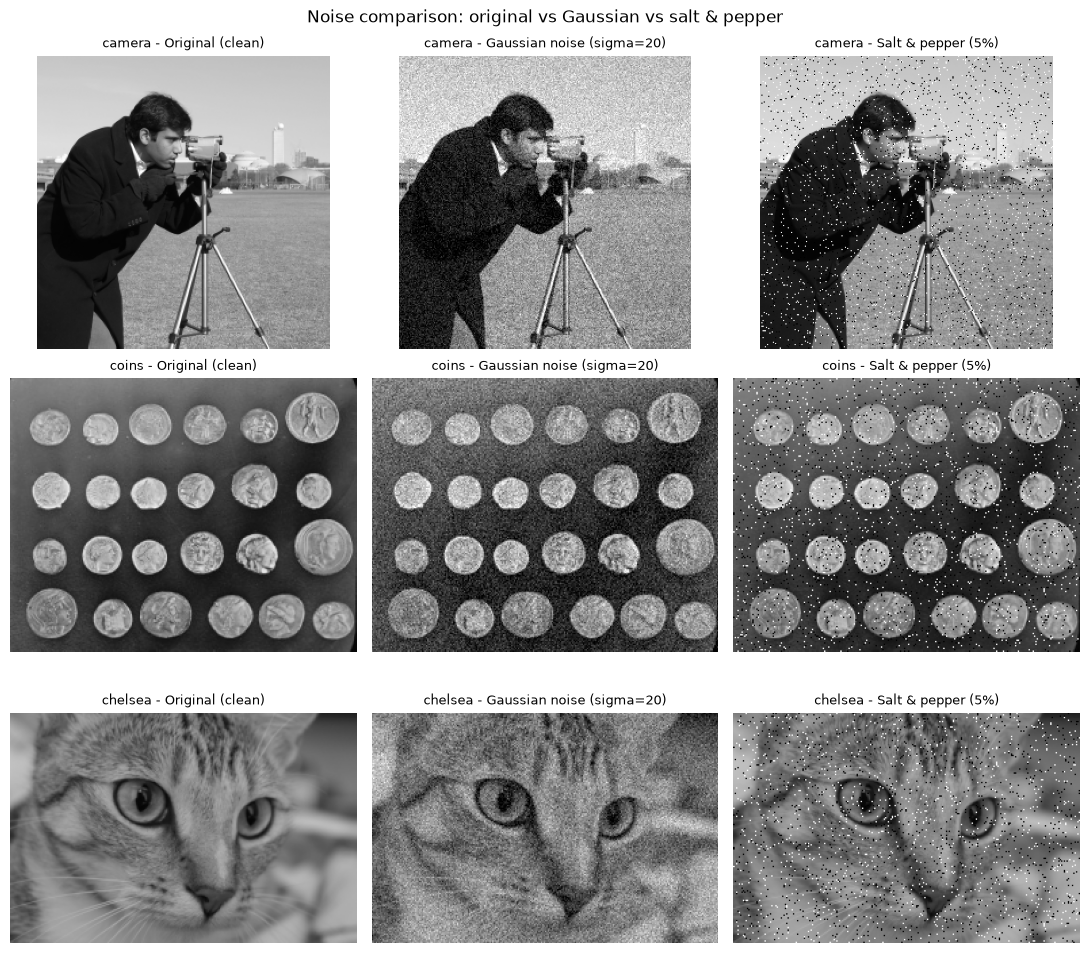

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for r, n in enumerate(NAMES):
    trio = [("Original (clean)", originals[n]),
            (NOISE_LABEL["gaussian"], noisy[(n, "gaussian")]),
            (NOISE_LABEL["saltpepper"], noisy[(n, "saltpepper")])]
    for c, (title, im) in enumerate(trio):
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{n} - {title}", fontsize=9)
        axes[r, c].axis("off")
plt.suptitle("Noise comparison: original vs Gaussian vs salt & pepper", fontsize=12)
plt.tight_layout()
plt.show()

## 6. Mean, Gaussian and median filters
`apply_filter` supports sizes 3, 5, 7. Filtered outputs are checked for dtype / range / shape (R1, R2) and the mean & Gaussian results are compared with my own `conv2d_loop`. Every score below is computed **against the clean original** (R6), never against the noisy image.

In [8]:
KINDS = ["mean", "gaussian", "median"]
SIZES = [3, 5, 7]

def apply_filter(img, kind, k):
    """Mean / Gaussian are computed in float64 and converted once at the end (R2);
    median uses cv2.medianBlur (uint8). Even sizes are rejected (R4)."""
    check_odd(k)
    if kind == "mean":
        return to_uint8(cv2.blur(img.astype(np.float64), (k, k)))
    if kind == "gaussian":
        return to_uint8(cv2.GaussianBlur(img.astype(np.float64), (k, k), 0))
    if kind == "median":
        return cv2.medianBlur(np.ascontiguousarray(img, dtype=np.uint8), k)
    raise ValueError("unknown filter: " + str(kind))

def psnr(img, ref):
    """Quality vs the CLEAN original (R6). Higher = closer to the clean image."""
    mse = np.mean((img.astype(np.float64) - ref.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255.0 ** 2 / mse)

# filter every noisy image with every filter at 3x3, 5x5 and 7x7
filtered = {}
for key, nimg in noisy.items():
    for kind in KINDS:
        for k in SIZES:
            filtered[(key, kind, k)] = apply_filter(nimg, kind, k)

# ---- compliance checks (R1, R2) ----
ok = all(f.dtype == np.uint8 and f.min() >= 0 and f.max() <= 255 and f.shape == noisy[key].shape
         for (key, kind, k), f in filtered.items())
print(f"Checked {len(filtered)} filtered images -> dtype uint8, range 0-255, same shape as input: {ok}")

# ---- mean filter: own conv2d_loop vs cv2.blur on a noisy image ----
key = ("camera", "gaussian")
mine = to_uint8(conv2d_loop(noisy[key], mean_kernel(3)))
diff = int(np.abs(mine.astype(int) - filtered[(key, "mean", 3)].astype(int)).max())
print(f"Mean 3x3 on noisy camera: conv2d_loop vs cv2.blur -> max difference = {diff} grey level(s)")
mine = to_uint8(conv2d_loop(noisy[key], gaussian_kernel(3)))
diff = int(np.abs(mine.astype(int) - filtered[(key, "gaussian", 3)].astype(int)).max())
print(f"Gaussian 3x3 on noisy camera: conv2d_loop vs cv2.GaussianBlur -> max difference = {diff} grey level(s)")

Checked 54 filtered images -> dtype uint8, range 0-255, same shape as input: True
Mean 3x3 on noisy camera: conv2d_loop vs cv2.blur -> max difference = 0 grey level(s)
Gaussian 3x3 on noisy camera: conv2d_loop vs cv2.GaussianBlur -> max difference = 0 grey level(s)


In [9]:
print("PSNR (dB) against the CLEAN original  (R6)  - higher is better")
head = f"{'image / noise':<24}{'noisy':>7} |" + "".join(f"{kd[:4]+' '+str(k):>7}" for kd in KINDS for k in SIZES)
print(head)
print("-" * len(head))
for key, nimg in noisy.items():
    clean = originals[key[0]]
    row = f"{key[0] + ' / ' + key[1]:<24}{psnr(nimg, clean):>7.1f} |"
    for kd in KINDS:
        for k in SIZES:
            row += f"{psnr(filtered[(key, kd, k)], clean):>7.1f}"
    print(row)
print()
print("Best filter per row (3x3):")
for key in noisy:
    clean = originals[key[0]]
    scores = {kd: psnr(filtered[(key, kd, 3)], clean) for kd in KINDS}
    best = max(scores, key=scores.get); worst = min(scores, key=scores.get)
    print(f"  {key[0]:8s} {key[1]:10s} best = {best:8s} worst = {worst}")

PSNR (dB) against the CLEAN original  (R6)  - higher is better
image / noise             noisy | mean 3 mean 5 mean 7 gaus 3 gaus 5 gaus 7 medi 3 medi 5 medi 7
------------------------------------------------------------------------------------------------
camera / gaussian          22.4 |   26.7   24.6   23.3   27.6   26.9   25.6   26.8   25.2   23.9
camera / saltpepper        17.7 |   24.5   23.9   22.9   24.5   25.0   24.6   29.8   25.7   24.1
coins / gaussian           22.2 |   26.3   24.1   22.6   27.2   26.4   25.0   26.7   26.1   24.9
coins / saltpepper         18.1 |   24.4   23.4   22.2   24.6   24.8   24.1   30.0   27.4   25.9
chelsea / gaussian         22.1 |   29.6   29.1   27.6   29.5   30.3   29.9   28.3   28.9   27.9
chelsea / saltpepper       18.7 |   26.9   27.9   27.0   26.4   28.0   28.4   34.2   31.0   29.0

Best filter per row (3x3):
  camera   gaussian   best = gaussian worst = mean
  camera   saltpepper best = median   worst = mean
  coins    gaussian   best = ga

### Filter comparison grid – 3×3 (mean vs Gaussian vs median on every noisy image)

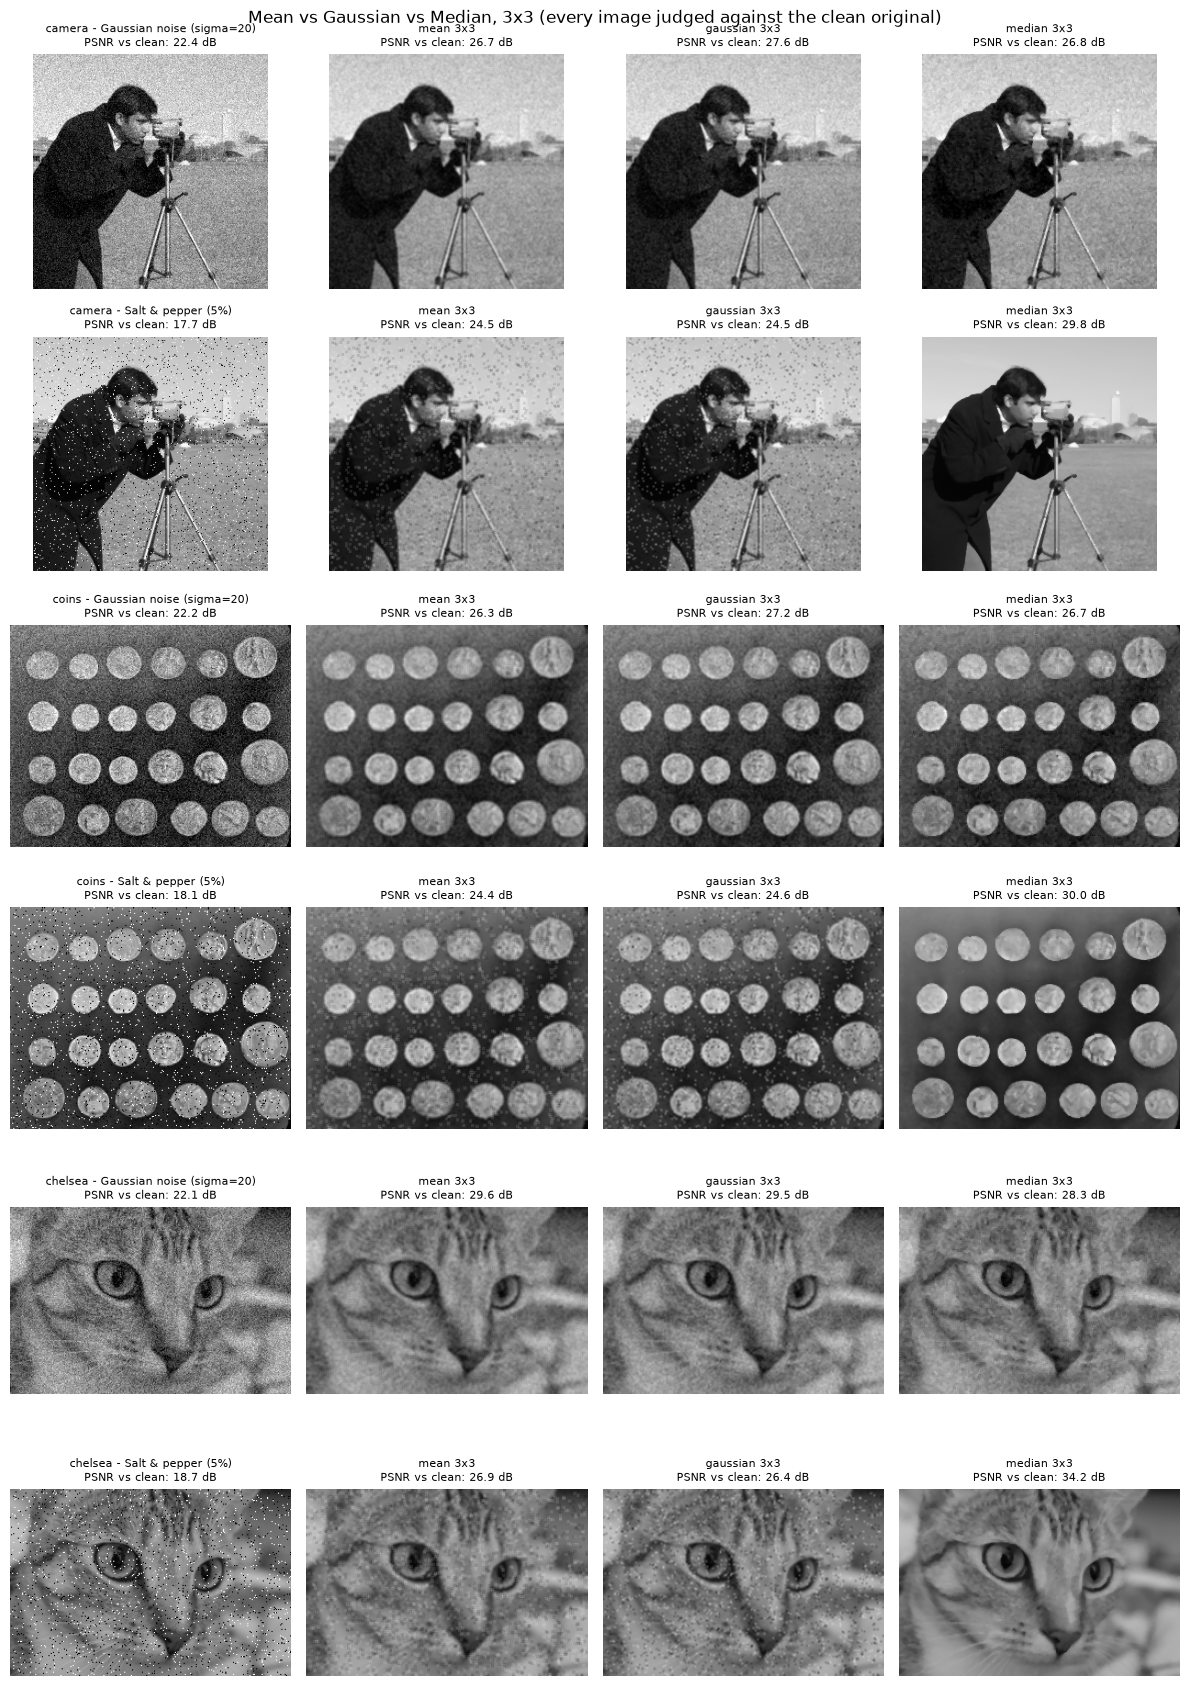

In [10]:
def filter_grid(k):
    keys = list(noisy.keys())
    fig, axes = plt.subplots(len(keys), 4, figsize=(12, 2.9 * len(keys)))
    for r, key in enumerate(keys):
        clean = originals[key[0]]
        panels = [(f"{key[0]} - {NOISE_LABEL[key[1]]}", noisy[key])]
        panels += [(f"{kd} {k}x{k}", filtered[(key, kd, k)]) for kd in KINDS]
        for c, (title, im) in enumerate(panels):
            axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
            axes[r, c].set_title(f"{title}\nPSNR vs clean: {psnr(im, clean):.1f} dB", fontsize=8)
            axes[r, c].axis("off")
    plt.suptitle(f"Mean vs Gaussian vs Median, {k}x{k} (every image judged against the clean original)", fontsize=12)
    plt.tight_layout()
    plt.show()

filter_grid(3)

### Same comparison at 5×5

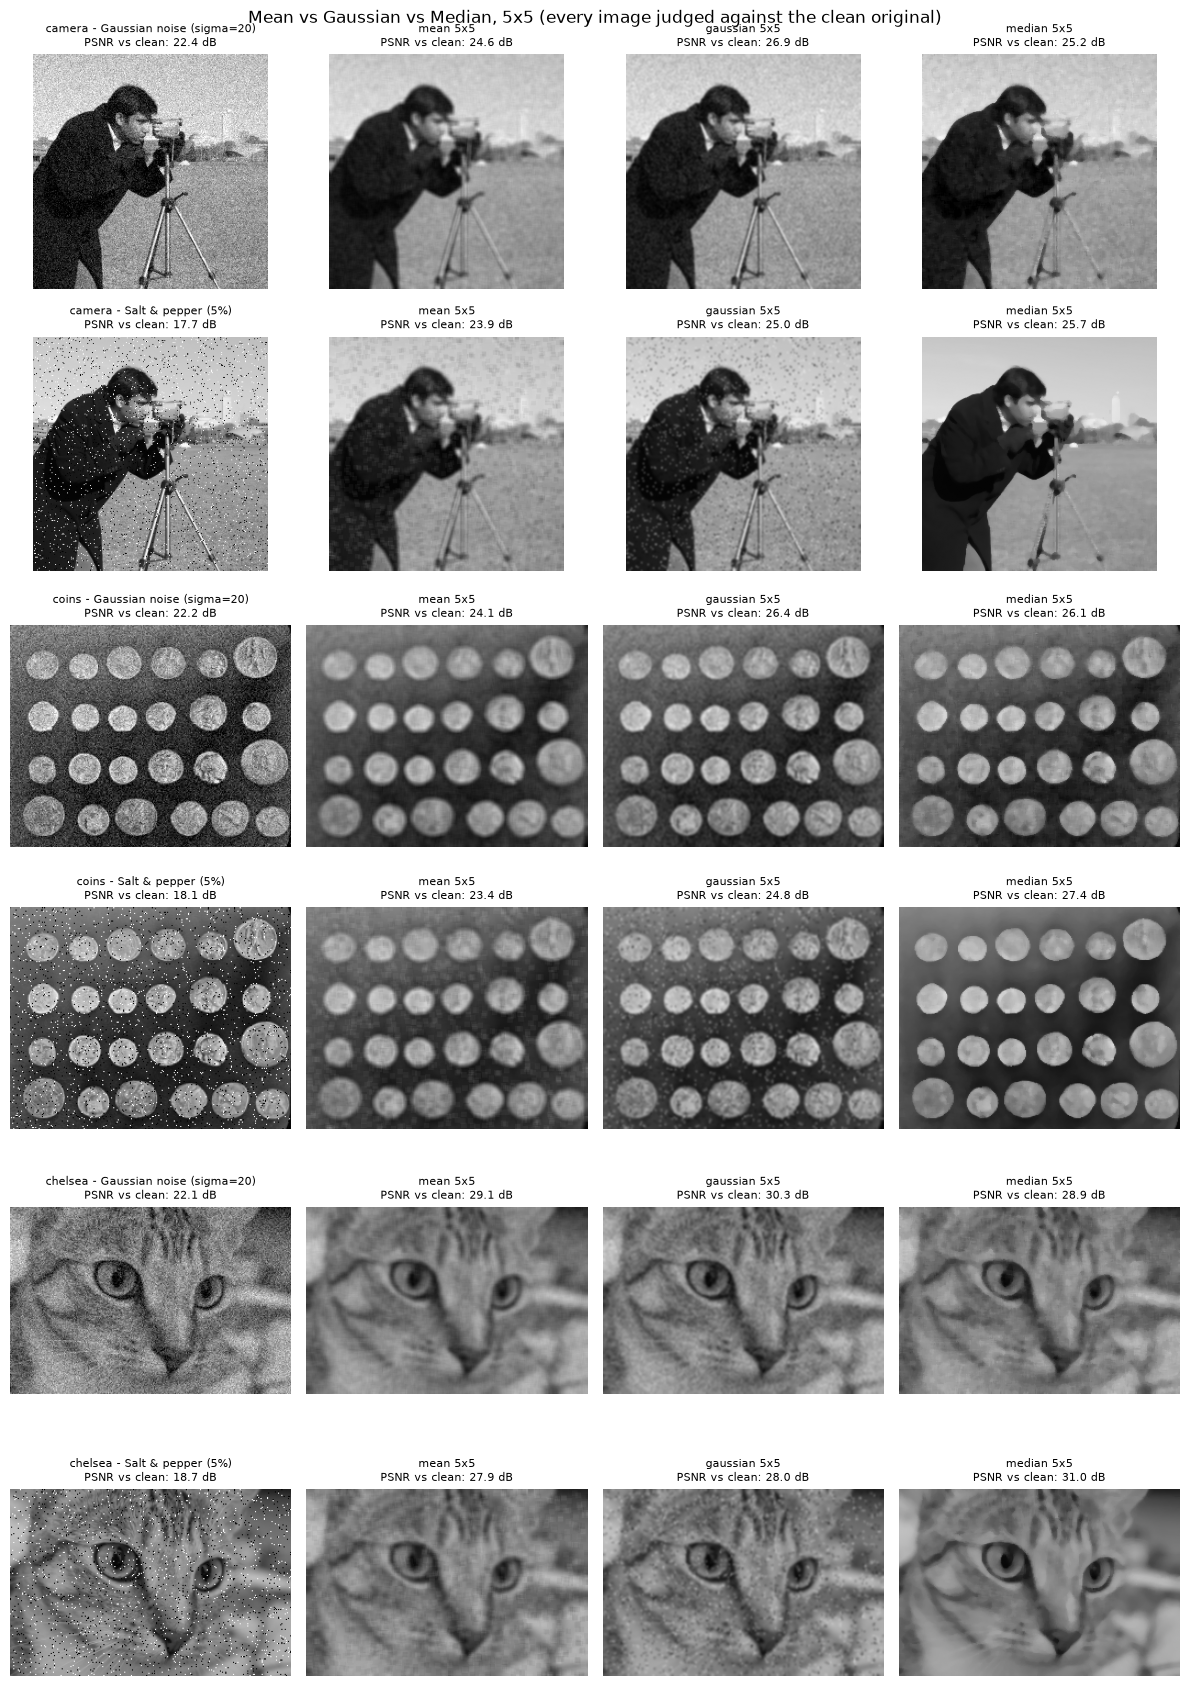

In [11]:
filter_grid(5)

### Same comparison at 7×7

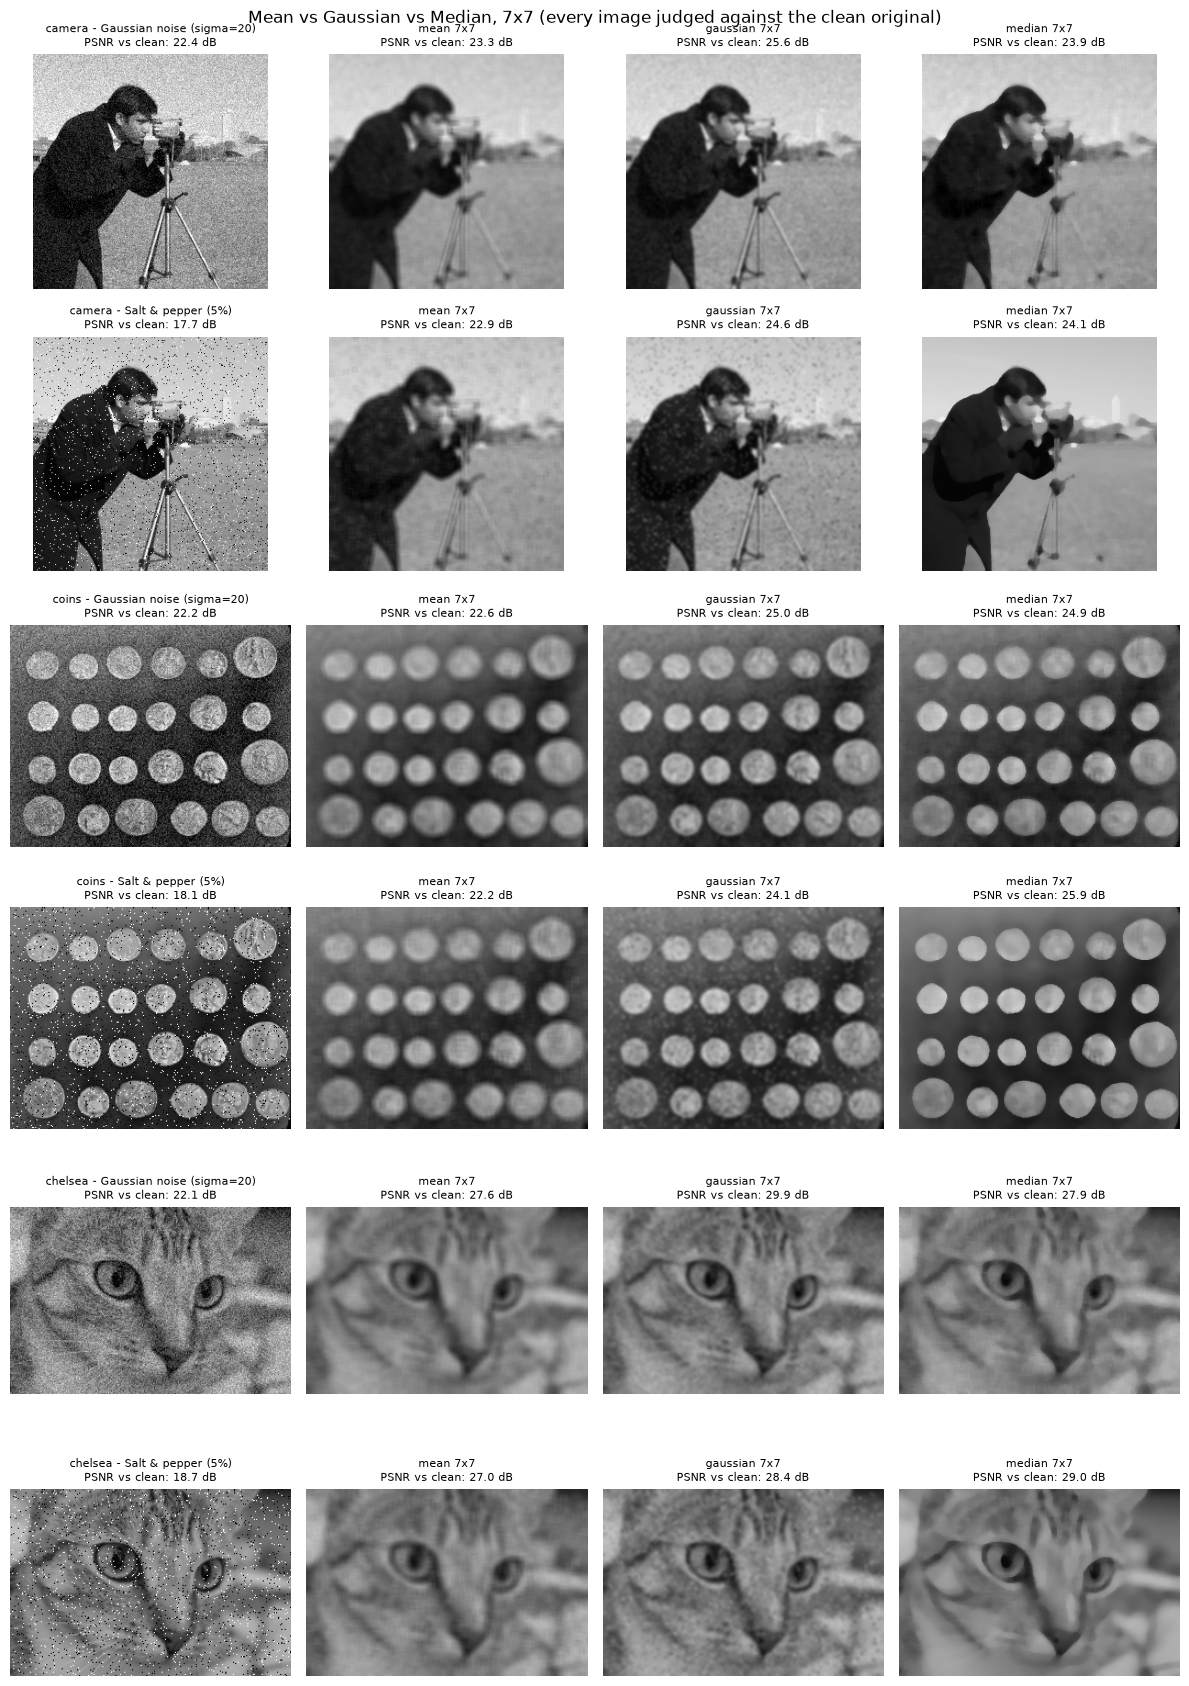

In [12]:
filter_grid(7)

### Kernel-size grid (filter × size) on the noisiest image

Noisiest image: camera - Salt & pepper (5%) (PSNR 17.7 dB)


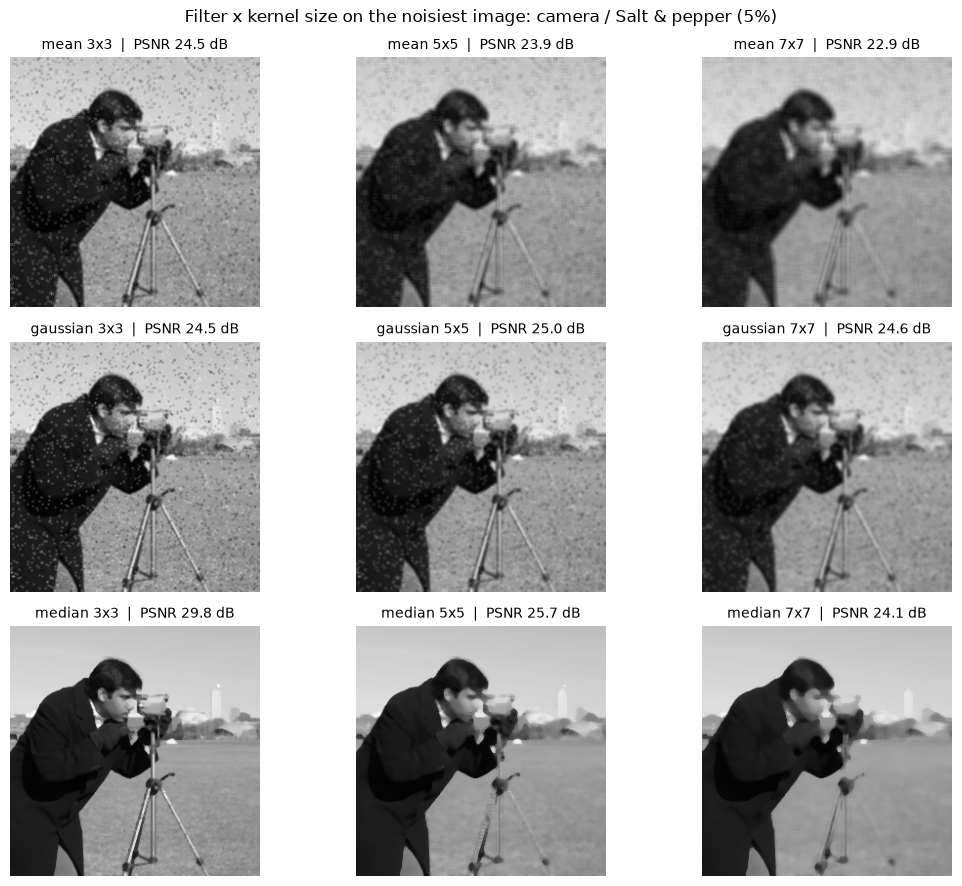

In [13]:
# noisiest image = lowest PSNR against its clean original
noisiest = min(noisy, key=lambda key: psnr(noisy[key], originals[key[0]]))
clean = originals[noisiest[0]]
print("Noisiest image:", noisiest[0], "-", NOISE_LABEL[noisiest[1]], f"(PSNR {psnr(noisy[noisiest], clean):.1f} dB)")

fig, axes = plt.subplots(3, 3, figsize=(11, 9))
for r, kd in enumerate(KINDS):
    for c, k in enumerate(SIZES):
        im = filtered[(noisiest, kd, k)]
        axes[r, c].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[r, c].set_title(f"{kd} {k}x{k}  |  PSNR {psnr(im, clean):.1f} dB", fontsize=10)
        axes[r, c].axis("off")
plt.suptitle(f"Filter x kernel size on the noisiest image: {noisiest[0]} / {NOISE_LABEL[noisiest[1]]}", fontsize=12)
plt.tight_layout()
plt.show()

### Closer look (clean camera image) – used for the observations
Filters are applied to the clean image here only to isolate what each filter does to a sharp edge and to fine detail.

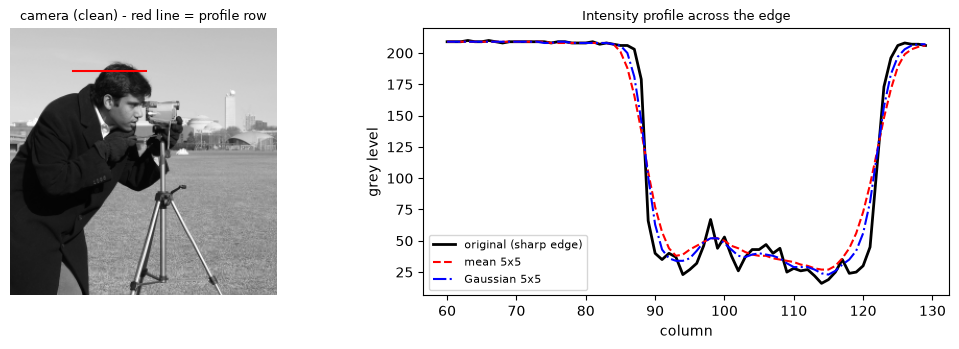

In [14]:
clean = originals["camera"]

# ---- sharp edge: one row of the clean camera image, sky -> dark coat/hair ----
ROW, C0, C1 = 40, 60, 130
mean5 = apply_filter(clean, "mean", 5)
gauss5 = apply_filter(clean, "gaussian", 5)
x = np.arange(C0, C1)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].imshow(clean, cmap="gray", vmin=0, vmax=255)
ax[0].plot([C0, C1], [ROW, ROW], color="red", lw=1.5)
ax[0].set_title("camera (clean) - red line = profile row", fontsize=9)
ax[0].axis("off")
ax[1].plot(x, clean[ROW, C0:C1], "k-", lw=2, label="original (sharp edge)")
ax[1].plot(x, mean5[ROW, C0:C1], "r--", label="mean 5x5")
ax[1].plot(x, gauss5[ROW, C0:C1], "b-.", label="Gaussian 5x5")
ax[1].set_title("Intensity profile across the edge", fontsize=9)
ax[1].set_xlabel("column"); ax[1].set_ylabel("grey level"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

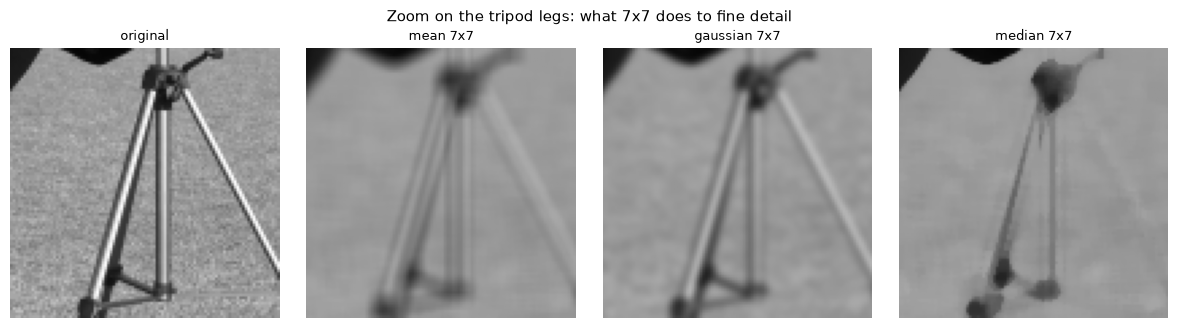

In [15]:
# ---- fine detail at 7x7: tripod legs of the clean camera image ----
r0, r1, c0, c1 = 150, 250, 90, 190
panels = [("original", clean)] + [(f"{kd} 7x7", apply_filter(clean, kd, 7)) for kd in KINDS]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
for ax, (t, im) in zip(axes, panels):
    ax.imshow(im[r0:r1, c0:c1], cmap="gray", vmin=0, vmax=255)
    ax.set_title(t, fontsize=9)
    ax.axis("off")
plt.suptitle("Zoom on the tripod legs: what 7x7 does to fine detail", fontsize=11)
plt.tight_layout()
plt.show()

## 7. Why kernel sizes must be odd (R4 demonstration)
An odd kernel has a single centre pixel, so the output pixel sits exactly in the middle of its window. An even kernel has no centre, so OpenCV (and my own `check_odd`) reject it.

In [16]:
# R4: an even kernel size must be rejected
import re
img = originals["camera"]
try:
    cv2.medianBlur(img, 4)
    print("cv2.medianBlur(img, 4) did NOT raise an error")
except Exception as e:
    print("cv2.medianBlur(img, 4) raised ->", type(e).__name__)
    m = re.search(r"Assertion failed[)] (.*?) in function", str(e))
    print("   reason: assertion failed ->", m.group(1) if m else str(e)[:120])

try:
    apply_filter(img, "mean", 4)
    print("apply_filter(img, 'mean', 4) did NOT raise an error")
except ValueError as e:
    print("my own apply_filter(img, 'mean', 4) raised ValueError ->", e)

print("Allowed odd sizes still work:", all(apply_filter(img, "median", k).shape == img.shape for k in (3, 5, 7)))

cv2.medianBlur(img, 4) raised -> error
   reason: assertion failed -> (ksize % 2 == 1) && (_src0.dims() <= 2 )
my own apply_filter(img, 'mean', 4) raised ValueError -> Kernel size must be odd: 3, 5 or 7 (got 4).
Allowed odd sizes still work: True


## 8. Dry-run exercises (hand calculation next to the code)

### Exercise 1 – Spike response
Window (one bright pixel, 255, surrounded by 40s):

```
[[ 40,  40,  40],
 [ 40, 255,  40],
 [ 40,  40,  40]]
```

**Mean 3×3:** sum = 8 × 40 + 255 = 320 + 255 = **575** → 575 / 9 = 63.89 → **64**

**Gaussian 3×3 (1-2-1 ÷ 16):** corners 1 × (4 × 40) = 160; edges 2 × (4 × 40) = 320; centre 4 × 255 = 1020 → total **1500** → 1500 / 16 = 93.75 → **94**

**Median 3×3:** sorted = 40, 40, 40, 40, 40, 40, 40, 40, 255 → middle (5th) value = **40**

→ the median completely removes the spike; the mean and Gaussian only spread it out (64 and 94 instead of 40).

In [17]:
win = np.array([[40, 40, 40],
                [40, 255, 40],
                [40, 40, 40]], dtype=np.uint8)

# --- hand calculation, step by step ---
mean_sum = int(win.sum())
print("MEAN   : sum of all 9 values =", " + ".join(str(v) for v in win.ravel()), "=", mean_sum)
print(f"         {mean_sum} / 9 = {mean_sum / 9:.4f}  -> rounds to {int(np.rint(mean_sum / 9))}")

G = np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
w = win.astype(np.int64)                    # int64 so that 255 x 4 does not overflow uint8
corners = int((w[[0, 0, 2, 2], [0, 2, 0, 2]] * 1).sum())
edges = int((w[[0, 1, 1, 2], [1, 0, 2, 1]] * 2).sum())
centre = int(w[1, 1] * 4)
g_sum = corners + edges + centre
print(f"GAUSS  : corners 1x(40x4) = {corners},  edges 2x(40x4) = {edges},  centre 4x255 = {centre}")
print(f"         total = {g_sum}  ->  {g_sum} / 16 = {g_sum / 16:.4f}  -> rounds to {int(np.rint(g_sum / 16))}")

srt = sorted(win.ravel().tolist())
print("MEDIAN : sorted values =", srt, "-> middle (5th) value =", srt[4])

# --- the notebook's own code ---
code_mean = conv2d_loop(win, mean_kernel(3))[1, 1]
code_gauss = conv2d_loop(win, G / 16.0)[1, 1]
code_median = cv2.medianBlur(win, 3)[1, 1]
print()
print(f"CODE   : mean = {code_mean:.4f} | gaussian = {code_gauss:.4f} | median = {code_median}")
print("Hand calculation matches code:",
      np.isclose(code_mean, mean_sum / 9) and np.isclose(code_gauss, g_sum / 16) and int(code_median) == srt[4])

MEAN   : sum of all 9 values = 40 + 40 + 40 + 40 + 255 + 40 + 40 + 40 + 40 = 575
         575 / 9 = 63.8889  -> rounds to 64
GAUSS  : corners 1x(40x4) = 160,  edges 2x(40x4) = 320,  centre 4x255 = 1020
         total = 1500  ->  1500 / 16 = 93.7500  -> rounds to 94
MEDIAN : sorted values = [40, 40, 40, 40, 40, 40, 40, 40, 255] -> middle (5th) value = 40

CODE   : mean = 63.8889 | gaussian = 93.7500 | median = 40
Hand calculation matches code: True


### Exercise 2 – Reflect padding at the top-left corner
Image: `[[10,20,30],[40,50,60],[70,80,90]]`. With `np.pad(..., mode="reflect")` the border mirrors the pixels **without repeating the edge pixel**, so the padded 5×5 image is

```
[[50, 40, 50, 60, 50],
 [20, 10, 20, 30, 20],
 [50, 40, 50, 60, 50],
 [80, 70, 80, 90, 80],
 [50, 40, 50, 60, 50]]
```

The 3×3 neighbourhood of pixel (0, 0) is the top-left 3×3 block of that padded image:

```
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]
```

**Mean 3×3 at (0, 0):** (50+40+50) + (20+10+20) + (50+40+50) = 140 + 50 + 140 = **330** → 330 / 9 = 36.67 → **37**

In [18]:
img2 = np.array([[10, 20, 30],
                 [40, 50, 60],
                 [70, 80, 90]], dtype=np.float64)

padded = np.pad(img2, 1, mode="reflect")
print("Reflect-padded 5x5 image:")
print(padded.astype(int))
nb = padded[0:3, 0:3]                       # the 3x3 neighbourhood of pixel (0, 0)
print("\nNeighbourhood averaged for pixel (0,0):")
print(nb.astype(int))
rows = nb.sum(axis=1).astype(int)
print(f"row sums = {rows[0]} + {rows[1]} + {rows[2]} = {int(nb.sum())}   ->   {int(nb.sum())} / 9 = {nb.sum() / 9:.4f}  -> rounds to {int(np.rint(nb.sum() / 9))}")

code_val = conv2d_loop(img2, mean_kernel(3))[0, 0]
cv_val = cv2.blur(img2, (3, 3))[0, 0]
print(f"\nCODE   : conv2d_loop = {code_val:.4f} | cv2.blur = {cv_val:.4f}")
print("Hand calculation matches code:", np.isclose(code_val, nb.sum() / 9) and np.isclose(cv_val, code_val))

Reflect-padded 5x5 image:
[[50 40 50 60 50]
 [20 10 20 30 20]
 [50 40 50 60 50]
 [80 70 80 90 80]
 [50 40 50 60 50]]

Neighbourhood averaged for pixel (0,0):
[[50 40 50]
 [20 10 20]
 [50 40 50]]
row sums = 140 + 50 + 140 = 330   ->   330 / 9 = 36.6667  -> rounds to 37

CODE   : conv2d_loop = 36.6667 | cv2.blur = 36.6667
Hand calculation matches code: True


## 9. Observations (answered from my own figures, judged against the clean original – R6)

**1. Gaussian noise – best and worst filter.**
*Best: the Gaussian filter.* In the 3×3 grid it has the highest PSNR on `camera` (27.6 dB vs 26.7 mean / 26.8 median) and on `coins` (27.2 vs 26.3 / 26.7), and it ties with the mean on `chelsea` (29.5 vs 29.6). Its weighted average removes the grain on the grass of `camera` and on the dark background of `coins` without wiping out the coin outlines.
*Worst: the median filter* (average 27.3 dB over the three images vs 27.5 for mean and 28.1 for Gaussian; on `chelsea` it is clearly last with 28.3 dB). Gaussian noise changes **every** pixel a little – there are no outliers to throw away – so choosing the middle value does not average the error out and leaves a blotchy, patchy texture in the flat areas (grass, cat fur background). The gap between mean and median on `camera`/`coins` is small (≤ 0.4 dB), but Gaussian is the clear winner.

**2. Salt-and-pepper noise – best filter and why the other two fail.**
*Best: the median filter* by a large margin: 29.8 dB (`camera`), 30.0 dB (`coins`), 34.2 dB (`chelsea`) against only 24.4–26.9 dB for mean and Gaussian. In the `camera` row of the 3×3 grid the black dots on the sky and grass are completely gone with the median, while with mean and Gaussian they are still visible as grey smudges.
*Why mean and Gaussian fail:* they **average** the spike into the result. In Exercise 1 a single 255 among 40s becomes 64 (mean) or 94 (Gaussian) instead of 40, so every 0 / 255 pixel turns into a grey blob that also contaminates its 8 neighbours. The median sorts the window; the 0 or 255 sits at an end of the list and is never selected (result 40).

**3. Mean vs Gaussian on a sharp edge.**
In the profile plot (row 40 of `camera`, the sky → head edge near column 88) the original falls from 203 to 66 within two pixels. After the 5×5 **mean** the brightness already starts to drop at column 85 (columns 84–92: 207, 201, 188, 166, 138, 105, 77, 57, 44) – a long, straight ramp of about 5–6 pixels, because all 25 pixels count equally and the dark pixels across the edge pull the value down early. After the 5×5 **Gaussian** the sky stays bright until column 85 (columns 84–92: 207, 206, 200, 181, 146, 101, 63, 43, 36) – the ramp is shorter (about 4 pixels) and closer to the original step, because the centre pixels have the largest weights and far pixels count little. Both blur the edge, but the Gaussian blurs it less.

**4. What happens to fine detail at 7×7.**
In the tripod zoom the original shows three thin, bright metal legs. With mean 7×7 and Gaussian 7×7 the legs are smeared into wide, faint grey bars and the grass texture disappears completely; with median 7×7 the thin legs are broken into dark blobs and the right leg is almost gone, because a leg is only a few pixels wide – narrower than the 7-pixel window – so it never becomes the middle value. The numbers agree: on `camera` with salt & pepper the median drops from 29.8 dB (3×3) to 25.7 (5×5) and 24.1 (7×7), and the mean falls from 24.5 to 22.9 dB (3×3 → 7×7): the larger window removes more noise but destroys more detail than it gains.

**5. Why must the kernel size be odd?**
An odd kernel (3×3, 5×5, 7×7) has one exact centre pixel, so the output value sits precisely on the pixel being computed and has the same number of neighbours on both sides. An even kernel (e.g. 4×4) has its "centre" between four pixels, which shifts the output by half a pixel, and an even-sized median window has no single middle value. That is why `cv2.medianBlur(img, 4)` raised an assertion error `(ksize % 2 == 1)` in Section 7 and my own `check_odd` rejects it as well.

## 10. Viva preparation (short answers)

**1. What is a kernel?** A small matrix of weights (e.g. 3×3) that slides over the image; each output pixel is the weighted sum of the neighbourhood under the kernel.

**2. Apply a 3×3 mean kernel to a 3×3 window.** Add the 9 values and divide by 9 (each weight is 1/9). Example: the spike window gives 575 / 9 ≈ 64 (Exercise 1).

**3. Why does the median remove a 255 spike but the mean does not?** The median only picks the middle value of the sorted window, so one extreme value ends up at the end of the list and is never chosen (result 40). The mean adds every value, so the spike pulls the average up (result 64).

**4. Why do the Gaussian weights sum to 16, and why divide by it?** 1+2+1+2+4+2+1+2+1 = 16. Dividing by 16 makes the weights sum to 1 (R3), so flat regions keep the same brightness after filtering.

**5. Why do we pad the border before filtering?** Border pixels do not have a full neighbourhood. Padding (reflect) supplies the missing neighbours so every pixel can be filtered and the output keeps the same size as the input (R1).

**6. Which filter for salt-and-pepper noise, and why?** The median filter – the 0 / 255 outliers sit at the ends of the sorted window and are discarded, while edges stay sharp.